<a href="https://colab.research.google.com/github/rehanaga86-tech/ML-Activity-1/blob/main/ML_CIE_ACT_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd

df = pd.read_csv("/yield_df.csv")

print("Shape (rows, columns):", df.shape)
print("\nColumn names and dtypes:\n", df.dtypes)
print("\nFirst 5 rows:\n", df.head())
print("\nLast 5 rows:\n", df.tail())

Shape (rows, columns): (28242, 8)

Column names and dtypes:
 Unnamed: 0                         int64
Area                              object
Item                              object
Year                               int64
hg/ha_yield                        int64
average_rain_fall_mm_per_year    float64
pesticides_tonnes                float64
avg_temp                         float64
dtype: object

First 5 rows:
    Unnamed: 0     Area         Item  Year  hg/ha_yield  \
0           0  Albania        Maize  1990        36613   
1           1  Albania     Potatoes  1990        66667   
2           2  Albania  Rice, paddy  1990        23333   
3           3  Albania      Sorghum  1990        12500   
4           4  Albania     Soybeans  1990         7000   

   average_rain_fall_mm_per_year  pesticides_tonnes  avg_temp  
0                         1485.0              121.0     16.37  
1                         1485.0              121.0     16.37  
2                         1485.0        

In [2]:
num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)
print("\nSummary statistics:\n", df[num_cols].describe())

Numerical columns: ['Unnamed: 0', 'Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']
Categorical columns: ['Area', 'Item']

Summary statistics:
          Unnamed: 0          Year    hg/ha_yield  \
count  28242.000000  28242.000000   28242.000000   
mean   14120.500000   2001.544296   77053.332094   
std     8152.907488      7.051905   84956.612897   
min        0.000000   1990.000000      50.000000   
25%     7060.250000   1995.000000   19919.250000   
50%    14120.500000   2001.000000   38295.000000   
75%    21180.750000   2008.000000  104676.750000   
max    28241.000000   2013.000000  501412.000000   

       average_rain_fall_mm_per_year  pesticides_tonnes      avg_temp  
count                    28242.00000       28242.000000  28242.000000  
mean                      1149.05598       37076.909344     20.542627  
std                        709.81215       59958.784665      6.312051  
min                         51.00000           0.040000     

In [3]:
missing_count = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)

missing_report = pd.DataFrame({
    "missing_count": missing_count,
    "missing_pct (%)": missing_pct
})
print(missing_report)

                               missing_count  missing_pct (%)
Unnamed: 0                                 0              0.0
Area                                       0              0.0
Item                                       0              0.0
Year                                       0              0.0
hg/ha_yield                                0              0.0
average_rain_fall_mm_per_year              0              0.0
pesticides_tonnes                          0              0.0
avg_temp                                   0              0.0


In [4]:
df_clean = df.copy()

if "Unnamed: 0" in df_clean.columns:
    df_clean = df_clean.drop(columns=["Unnamed: 0"])

for col in ["average_rain_fall_mm_per_year", "pesticides_tonnes", "avg_temp"]:
    if col in df_clean.columns and df_clean[col].isnull().sum() > 0:
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in ["Area", "Item"]:
    if col in df_clean.columns and df_clean[col].isnull().sum() > 0:
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("Remaining missing values:\n", df_clean.isnull().sum())

Remaining missing values:
 Area                             0
Item                             0
Year                             0
hg/ha_yield                      0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
avg_temp                         0
dtype: int64


In [5]:
dup_count = df_clean.duplicated().sum()
print("Duplicate rows found:", dup_count)

if dup_count > 0:
    print(df_clean[df_clean.duplicated(keep=False)].head(6))
    df_clean = df_clean.drop_duplicates().reset_index(drop=True)
    print("Shape after removing duplicates:", df_clean.shape)

for col in ["Area", "Item"]:
    if col in df_clean.columns:
        before_unique = df_clean[col].nunique()
        df_clean[col] = df_clean[col].astype(str).str.strip()
        after_unique = df_clean[col].nunique()
        print(f"{col}: {before_unique} -> {after_unique} unique values after stripping spaces")

Duplicate rows found: 2310
            Area         Item  Year  hg/ha_yield  \
2082  Bangladesh        Maize  1990        10015   
2083  Bangladesh        Maize  1990        10015   
2084  Bangladesh     Potatoes  1990        91410   
2085  Bangladesh     Potatoes  1990        91410   
2086  Bangladesh  Rice, paddy  1990        25661   
2087  Bangladesh  Rice, paddy  1990        25661   

      average_rain_fall_mm_per_year  pesticides_tonnes  avg_temp  
2082                         2666.0             1266.0     25.98  
2083                         2666.0             1266.0     25.98  
2084                         2666.0             1266.0     25.98  
2085                         2666.0             1266.0     25.98  
2086                         2666.0             1266.0     25.98  
2087                         2666.0             1266.0     25.98  
Shape after removing duplicates: (25932, 7)
Area: 101 -> 101 unique values after stripping spaces
Item: 10 -> 10 unique values after stripp

Summary statistics:
                Year    hg/ha_yield  average_rain_fall_mm_per_year  \
count  25932.000000   25932.000000                   25932.000000   
mean    2001.556455   76978.132925                    1146.836688   
std        7.055924   84647.605552                     717.391098   
min     1990.000000      50.000000                      51.000000   
25%     1995.000000   19996.000000                     593.000000   
50%     2001.000000   39530.000000                    1083.000000   
75%     2008.000000  104168.000000                    1668.000000   
max     2013.000000  501412.000000                    3240.000000   

       pesticides_tonnes      avg_temp  
count       25932.000000  25932.000000  
mean        34782.573241     20.422251  
std         57228.568244      6.439402  
min             0.040000      1.300000  
25%          1597.000000     16.580000  
50%         15373.000000     21.420000  
75%         45620.000000     26.060000  
max        367778.000000     

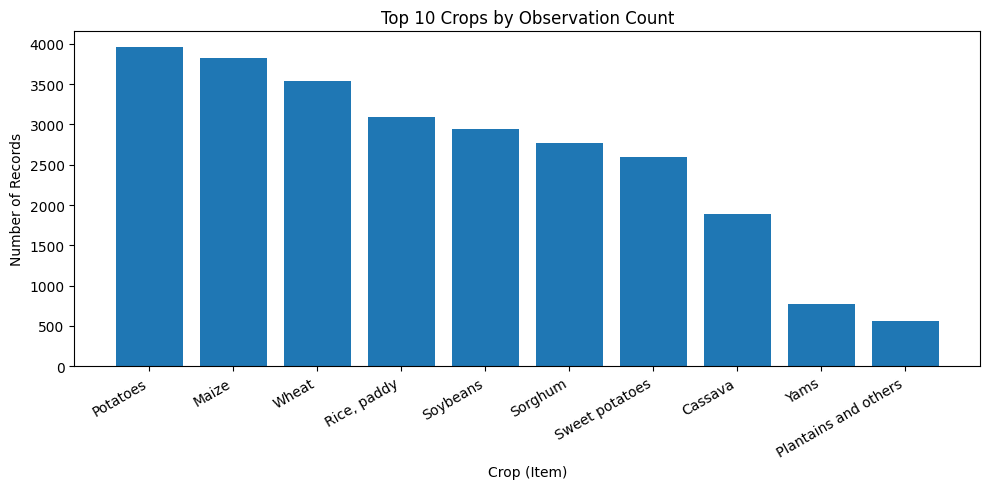

In [7]:
import matplotlib.pyplot as plt

print("Summary statistics:\n", df_clean.describe())
print("\nTop 10 Crops (Item) counts:\n", df_clean["Item"].value_counts().head(10))

# Plot 1: Bar chart of top 10 crops by record count
top_crops = df_clean["Item"].value_counts().head(10)
plt.figure(figsize=(10, 5))
plt.bar(top_crops.index, top_crops.values)
plt.title("Top 10 Crops by Observation Count")
plt.xlabel("Crop (Item)")
plt.ylabel("Number of Records")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()



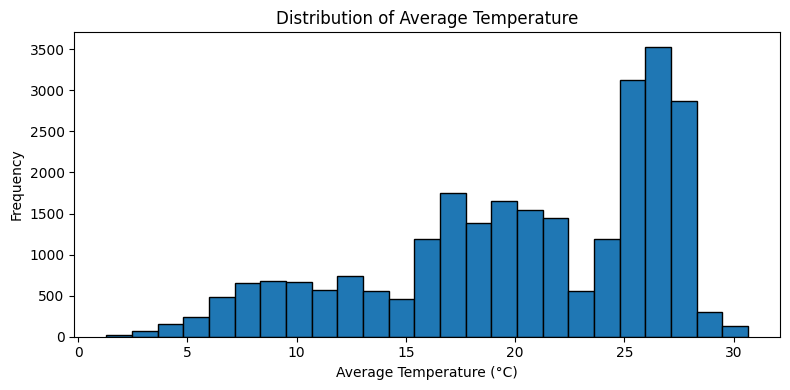

In [9]:

plt.figure(figsize=(8, 4))
plt.hist(df_clean["avg_temp"], bins=25, edgecolor="black")
plt.title("Distribution of Average Temperature")
plt.xlabel("Average Temperature (°C)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


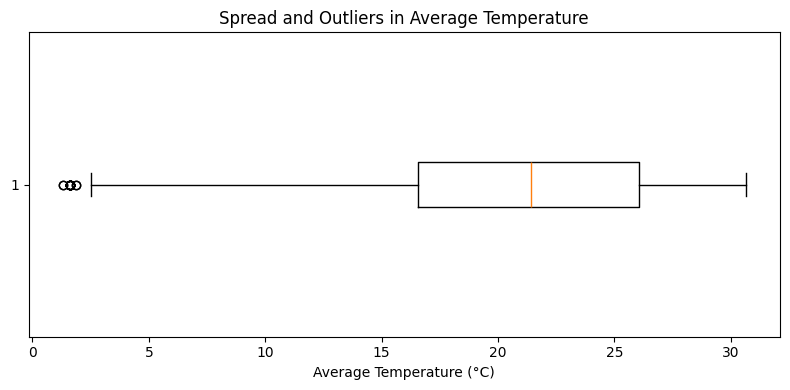

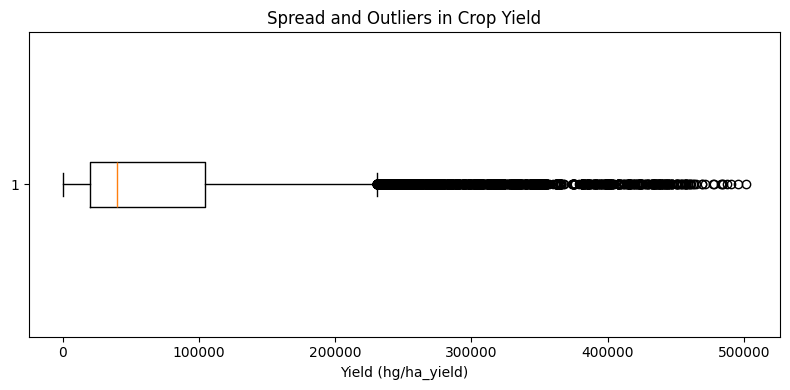

In [16]:

plt.figure(figsize=(8, 4))
plt.boxplot(df_clean["avg_temp"], vert=False)
plt.title("Spread and Outliers in Average Temperature")
plt.xlabel("Average Temperature (°C)")
plt.tight_layout()


plt.figure(figsize=(8, 4))
plt.boxplot(df_clean["hg/ha_yield"], vert=False)
plt.title("Spread and Outliers in Crop Yield")
plt.xlabel("Yield (hg/ha_yield)")
plt.tight_layout()
plt.show()


In [11]:
df_encoded = pd.get_dummies(df_clean, columns=["Area", "Item"], drop_first=True, dtype=int)

print("Shape before encoding:", df_clean.shape)
print("Shape after one-hot encoding:", df_encoded.shape)

Shape before encoding: (25932, 7)
Shape after one-hot encoding: (25932, 114)


In [12]:
from sklearn.preprocessing import StandardScaler

target_col = "hg/ha_yield"
features_to_scale = [
    c for c in ["Year", "average_rain_fall_mm_per_year", "pesticides_tonnes", "avg_temp"]
    if c in df_encoded.columns
]

scaler = StandardScaler()
df_prepared = df_encoded.copy()
df_prepared[features_to_scale] = scaler.fit_transform(df_prepared[features_to_scale])

print("Scaled input features:", features_to_scale)
print("Target column left unscaled:", target_col)

Scaled input features: ['Year', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']
Target column left unscaled: hg/ha_yield


In [13]:
output_filename = "prepared_crop_yield_dataset.csv"
df_prepared.to_csv(output_filename, index=False)

df_check = pd.read_csv(output_filename)
print("Saved file:", output_filename)
print("Final shape:", df_check.shape)
print("Remaining missing values:", df_check.isnull().sum().sum())
print("Remaining duplicate rows:", df_check.duplicated().sum())
print("\nSample of prepared data:\n", df_check.head())

Saved file: prepared_crop_yield_dataset.csv
Final shape: (25932, 114)
Remaining missing values: 0
Remaining duplicate rows: 0

Sample of prepared data:
        Year  hg/ha_yield  average_rain_fall_mm_per_year  pesticides_tonnes  \
0 -1.637869        36613                       0.471388          -0.605681   
1 -1.637869        66667                       0.471388          -0.605681   
2 -1.637869        23333                       0.471388          -0.605681   
3 -1.637869        12500                       0.471388          -0.605681   
4 -1.637869         7000                       0.471388          -0.605681   

   avg_temp  Area_Algeria  Area_Angola  Area_Argentina  Area_Armenia  \
0 -0.629302             0            0               0             0   
1 -0.629302             0            0               0             0   
2 -0.629302             0            0               0             0   
3 -0.629302             0            0               0             0   
4 -0.629302       